In [1]:
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

In [2]:
heart = pd.read_csv("data/heart.csv")

X=heart.drop("target",axis=1)
y=heart["target"]

X_train,X_test,y_train,y_test=train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [3]:
model=GaussianNB()
model.fit(X_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[109.,133.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.45,0.55]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,2.776e-06
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['age','sex','cp',...,'slope','ca','thal']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 13)","[[56.83, 0.82, 0.53,..., 1.19, 1.09, 2.52], [52.52, 0.53, 1.37,..., 1.61, 0.35, 2.12]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 13)","[[64.06, 0.15, 0.84,..., 0.32, 1. , 0.43], [92.63, 0.25, 0.89,..., 0.33, 0.71, 0.21]]"


accuracy_score: 0.8688524590163934
Precision Score: 0.9
recall_score: 0.84375

Classification report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87        29
           1       0.90      0.84      0.87        32

    accuracy                           0.87        61
   macro avg       0.87      0.87      0.87        61
weighted avg       0.87      0.87      0.87        61

Confusion matrix:
[[26  3]
 [ 5 27]]


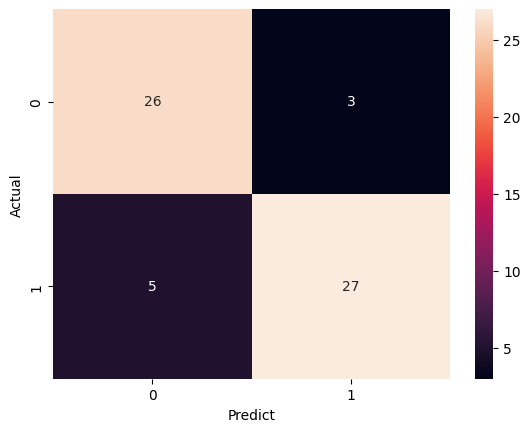

In [9]:
y_pred=model.predict(X_test)

print(f"accuracy_score: {accuracy_score(y_test,y_pred)}")
print(f"Precision Score: {precision_score(y_test,y_pred)}")
print(f"recall_score: {recall_score(y_test,y_pred)}")

print("\nClassification report:")
print(classification_report(y_test, y_pred))

print("Confusion matrix:")
cd=confusion_matrix(y_test, y_pred)
print(cd)

sns.heatmap(cd,annot=True)
plt.xlabel("Predict")
plt.ylabel("Actual")
plt.show()

In [16]:
heart

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
298,57,0,0,140,241,0,1,123,1,0.2,1,0,3,0
299,45,1,3,110,264,0,1,132,0,1.2,1,0,3,0
300,68,1,0,144,193,1,1,141,0,3.4,1,2,3,0
301,57,1,0,130,131,0,1,115,1,1.2,1,1,3,0


In [31]:
# Patient input
patient = pd.DataFrame([{
    "age": 21,
    "sex": 1,
    "cp": 2,
    "trestbps": 120,
    "chol": 180,
    "fbs": 0,
    "restecg": 0,
    "thalach": 180,
    "exang": 0,
    "oldpeak": 0.0,
    "slope": 2,
    "ca": 0,
    "thal": 2
}])

# Prediction
prediction = model.predict(patient)[0]


if prediction == 1:
    print("Heart Disease: Predicted Positive")
else:
    print("Heart Disease: Predicted Negative")
    


Heart Disease: Predicted Positive


In [30]:
print("Prediction:", model.predict(patient))
print("Probability:", model.predict_proba(patient))
print("Classes:", model.classes_)

Prediction: [1]
Probability: [[2.74730674e-05 9.99972527e-01]]
Classes: [0 1]


In [26]:
import joblib

joblib.dump(model, "heart_model.pkl")
joblib.dump(list(X_train.columns), "heart_features.pkl")

['heart_features.pkl']